# Joint Analysis — Ridge vs Random Forest vs Gradient Boosting

This notebook brings the three model notebooks together for Phase 4:

1. A unified comparison table against the mean-price baseline.
2. Error analysis across price tiers for all three models.
3. A check of whether geographic indicators (coordinates, area codes, neighbourhood codes) improve performance.
4. A draft of the joint conclusion.

Metrics come from the files each member exported to `results/`. All models use the same eligible
records, the same 81 inputs and the same chronological split (train 2017–2023, validation 2024, test 2025).

In [1]:
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from shared_preprocessing import load_splits, NUMERIC_FEATURES, CATEGORICAL_FEATURES

results_dir = Path("../results")
X_train, y_train, X_val, y_val, X_test, y_test = load_splits("../data/stage2_outputs")

def evaluate_predictions(name, y_true, y_pred):
    return {"model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

## 1. Unified Comparison Table

**Note on the Gradient Boosting validation row.** In `gb_metrics.csv`, the validation RMSE (\$196,645.88)
is the RMSE of the *default* HistGB model, while the MAE and R² belong to the tuned model. Because
R² = 1 − SSE/SST, the tuned model's validation RMSE follows exactly from its reported R² and the variance of
the 2024 prices, so we correct it here. Kayla should update `gb_metrics.csv` to match.

In [2]:
ridge = pd.read_csv(results_dir / "ridge_metrics.csv")
rf = pd.read_csv(results_dir / "rf_metrics.csv")
gb = pd.read_csv(results_dir / "gb_metrics.csv")

# Correct GB validation RMSE from its own reported R²: RMSE = sqrt((1 - R²) * Var(y_val))
gb_val = gb["split"] == "Validation 2024"
reported_rmse = float(gb.loc[gb_val, "RMSE"].iloc[0])
gb.loc[gb_val, "RMSE"] = np.sqrt((1 - gb.loc[gb_val, "R2"]) * np.var(y_val.to_numpy()))
print(f"GB validation RMSE: reported ${reported_rmse:,.0f} -> consistent with R² ${gb.loc[gb_val, 'RMSE'].iloc[0]:,.0f}")

gb["model"] = gb["model"].replace({"HistGB": "Gradient Boosting"})
comparison = pd.concat([
    ridge[ridge["model"] == "Mean baseline"],
    ridge[ridge["model"] == "Ridge"],
    rf[rf["model"] == "Random Forest"],
    gb,
], ignore_index=True)

order = {"Mean baseline": 0, "Ridge": 1, "Random Forest": 2, "Gradient Boosting": 3}
comparison = comparison.sort_values(["split", "model"], key=lambda s: s.map(order) if s.name == "model" else s,
                                    ascending=[False, True]).reset_index(drop=True)

baseline_test_mae = comparison.query("split == 'Test 2025' and model == 'Mean baseline'")["MAE"].iloc[0]
comparison["MAE vs baseline"] = np.where(
    comparison["split"] == "Test 2025",
    (comparison["MAE"] / baseline_test_mae - 1).map(lambda v: f"{v:+.1%}"), "")

table = comparison.copy()
for col in ["MAE", "RMSE"]:
    table[col] = table[col].map(lambda v: f"{v:,.0f}")
table["R2"] = table["R2"].map(lambda v: f"{v:.4f}")
table = table.rename(columns={"MAE": "MAE (USD)", "RMSE": "RMSE (USD)", "R2": "R²"})
print(table.to_markdown(index=False))

GB validation RMSE: reported $196,646 -> consistent with R² $186,095
| split           | model             |   MAE (USD) |   RMSE (USD) |      R² | MAE vs baseline   |
|:----------------|:------------------|------------:|-------------:|--------:|:------------------|
| Validation 2024 | Mean baseline     |     227,824 |      444,017 | -0.0463 |                   |
| Validation 2024 | Ridge             |     126,786 |      231,855 |  0.7147 |                   |
| Validation 2024 | Random Forest     |     105,920 |      193,432 |  0.8014 |                   |
| Validation 2024 | Gradient Boosting |     107,526 |      186,095 |  0.8162 |                   |
| Test 2025       | Mean baseline     |     249,128 |      551,843 | -0.0518 | +0.0%             |
| Test 2025       | Ridge             |     147,267 |      348,008 |  0.5817 | -40.9%            |
| Test 2025       | Random Forest     |     124,356 |      272,307 |  0.7439 | -50.1%            |
| Test 2025       | Gradient Boosting | 

## 2. Where Do All Models Struggle? Price-Tier Error Analysis

Each member exported test-set errors by actual price band (signed error = predicted − actual,
so negative means underprediction). We combine them below.

| Price band   |   Records |   Ridge MAE |   RF MAE |   GB MAE |   Ridge bias |   RF bias |   GB bias | Ridge MAE % of price   | RF MAE % of price   | GB MAE % of price   |
|:-------------|----------:|------------:|---------:|---------:|-------------:|----------:|----------:|:-----------------------|:--------------------|:--------------------|
| Up to $250k  |      8694 |      69,670 |   55,004 |   54,611 |      -18,034 |     3,237 |    -5,219 | 44%                    | 35%                 | 34%                 |
| $250k–$500k  |     14348 |     104,077 |   83,886 |   92,596 |      -85,710 |   -72,300 |   -82,770 | 29%                    | 23%                 | 26%                 |
| $500k–$1M    |      6070 |     177,853 |  170,209 |  174,848 |     -144,053 |  -158,997 |  -162,283 | 26%                    | 25%                 | 26%                 |
| Above $1M    |      2423 |     604,820 |  497,978 |  456,875 |     -579,710 |  -468,980 |  -421,125 | 35%                    | 28%   

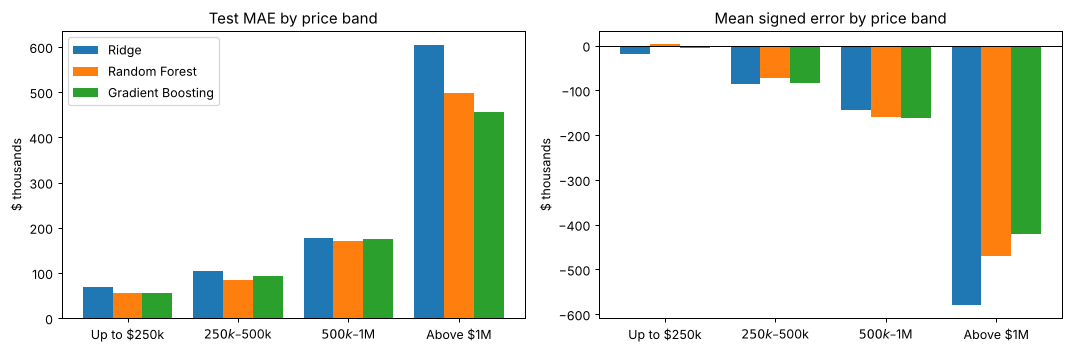

In [3]:
bands = ["Up to $250k", "$250k–$500k", "$500k–$1M", "Above $1M"]

ridge_b = pd.read_csv(results_dir / "ridge_errors_by_price_band.csv")
rf_b = pd.read_csv(results_dir / "rf_errors_by_price_band.csv")
gb_b = pd.read_csv(results_dir / "gb_errors_by_price_band.csv").rename(
    columns={"test_mae": "MAE", "count": "records"})
for frame in (ridge_b, rf_b, gb_b):        # same band order in every file; harmonise labels
    frame["price_band"] = bands

band_table = pd.DataFrame({
    "Price band": bands,
    "Records": ridge_b["records"].to_numpy(),
    "Ridge MAE": ridge_b["MAE"].to_numpy(),
    "RF MAE": rf_b["MAE"].to_numpy(),
    "GB MAE": gb_b["MAE"].to_numpy(),
    "Ridge bias": ridge_b["mean_error"].to_numpy(),
    "RF bias": rf_b["mean_error"].to_numpy(),
    "GB bias": gb_b["mean_error"].to_numpy(),
})
assert (gb_b["records"].to_numpy() == band_table["Records"]).all()

# Mean absolute error as a share of the band's average price (relative error)
test_prices = pd.cut(y_test, bins=[0, 250_000, 500_000, 1_000_000, np.inf], labels=bands, include_lowest=True)
band_mean_price = y_test.groupby(test_prices, observed=True).mean().to_numpy()
for m in ["Ridge", "RF", "GB"]:
    band_table[f"{m} MAE % of price"] = band_table[f"{m} MAE"] / band_mean_price

display_table = band_table.copy()
for c in display_table.columns:
    if "%" in c:
        display_table[c] = display_table[c].map(lambda v: f"{v:.0%}")
    elif c not in ("Price band", "Records"):
        display_table[c] = display_table[c].map(lambda v: f"{v:,.0f}")
print(display_table.to_markdown(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(bands)); w = 0.27
for i, (m, label) in enumerate([("Ridge", "Ridge"), ("RF", "Random Forest"), ("GB", "Gradient Boosting")]):
    axes[0].bar(x + (i - 1) * w, band_table[f"{m} MAE"] / 1000, w, label=label)
    axes[1].bar(x + (i - 1) * w, band_table[f"{m} bias"] / 1000, w, label=label)
for ax, title in [(axes[0], "Test MAE by price band"), (axes[1], "Mean signed error by price band")]:
    ax.set_xticks(x); ax.set_xticklabels(bands); ax.set_title(title); ax.set_ylabel("$ thousands")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[0].legend()
plt.tight_layout(); plt.show()

In [4]:
# Overall direction of errors on the 2025 test set (from exported test predictions)
ridge_pred = pd.read_csv(results_dir / "ridge_test_predictions.csv")
rf_pred = pd.read_csv(results_dir / "rf_test_predictions.csv")

price_drift = pd.DataFrame({
    "period": ["Training 2017–2023", "Validation 2024", "Test 2025"],
    "mean price": [y_train.mean(), y_val.mean(), y_test.mean()],
    "median price": [y_train.median(), y_val.median(), y_test.median()],
})
display(price_drift.round(0))

direction = pd.DataFrame([
    {"model": name, "share underpredicted": (p["error"] < 0).mean(), "median signed error": p["error"].median()}
    for name, p in [("Ridge", ridge_pred), ("Random Forest", rf_pred)]
])
display(direction.round(3))

,period,mean price,median price
0,Training 2017–2023,350714.0,270000.0
1,Validation 2024,444157.0,339900.0
2,Test 2025,473135.0,353000.0


,model,share underpredicted,median signed error
0,Ridge,0.807,-89418.488
1,Random Forest,0.794,-73796.124


## 3. Do Geographic Indicators Improve Performance?

We retrain Ridge and Gradient Boosting (both quick to fit) with their selected hyperparameters on four
input sets, keeping everything else fixed, and compare validation and test error:

| Input set | Inputs |
|---|---|
| **All shared inputs** | the 81 shared features |
| **No geographic identifiers** | drops coordinates and area codes: latitude, longitude, city, ZIP, municipality, elementary and secondary school district (74 inputs) |
| **Property only** | the 25 `char_*` features: no location or neighbourhood context at all |
| **+ Neighbourhood codes** | the 81 features plus the assessor's township and neighbourhood codes (83 inputs) |

Neighbourhood and township codes were not in the shared input set; they are taken from the `meta_*`
files, which contain only location codes known before a sale. Random Forest is too slow to refit four
times, so for it we use the grouped permutation test from `03b_RandomForest.ipynb`.

The "All shared inputs" rows are fresh refits, so they can differ slightly from each member's exported
numbers (HistGB's built-in early stopping is version-sensitive). Comparisons are always made within the same refit.

In [5]:
geo_identifiers = ["loc_latitude", "loc_longitude", "loc_property_city", "loc_property_zip",
                   "loc_tax_municipality_name", "loc_school_elementary_district_geoid",
                   "loc_school_secondary_district_geoid"]

meta = {s: pd.read_parquet(f"../data/stage2_outputs/meta_{s}.parquet") for s in ["train", "val", "test"]}
def with_neighbourhood(X, split):
    out = X.copy()
    out["meta_township_code"] = meta[split]["meta_township_code"].to_numpy()
    out["meta_nbhd_code"] = meta[split]["meta_nbhd_code"].to_numpy()
    return out

def make_encoder(kind, numeric, categorical):
    if kind == "ridge":
        return ColumnTransformer([
            ("num", StandardScaler(), numeric),
            ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), categorical)])
    return ColumnTransformer([
        ("num", "passthrough", numeric),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical)])

ridge_cfg = json.loads((results_dir / "ridge_config.json").read_text())
gb_cfg = json.loads((results_dir / "gb_config.json").read_text())

def make_model(kind):
    if kind == "ridge":
        return Ridge(alpha=ridge_cfg["alpha"], solver=ridge_cfg["solver"])
    return HistGradientBoostingRegressor(random_state=42, **gb_cfg)

input_sets = {
    "All shared inputs": (NUMERIC_FEATURES, CATEGORICAL_FEATURES, False),
    "No geographic identifiers": ([f for f in NUMERIC_FEATURES if f not in geo_identifiers],
                                  [f for f in CATEGORICAL_FEATURES if f not in geo_identifiers], False),
    "Property only": ([f for f in NUMERIC_FEATURES if f.startswith("char_")],
                      [f for f in CATEGORICAL_FEATURES if f.startswith("char_")], False),
    "+ Neighbourhood codes": (NUMERIC_FEATURES, CATEGORICAL_FEATURES + ["meta_township_code", "meta_nbhd_code"], True),
}

ablation_rows = []
for kind, label in [("ridge", "Ridge"), ("gb", "Gradient Boosting")]:
    for set_name, (num, cat, add_nbhd) in input_sets.items():
        Xtr_s, Xva_s, Xte_s = X_train, X_val, X_test
        if add_nbhd:
            Xtr_s, Xva_s, Xte_s = (with_neighbourhood(X_train, "train"),
                                   with_neighbourhood(X_val, "val"), with_neighbourhood(X_test, "test"))
        pipe = make_pipeline(make_encoder(kind, num, cat), make_model(kind)).fit(Xtr_s, y_train)
        for split, X, y in [("Validation 2024", Xva_s, y_val), ("Test 2025", Xte_s, y_test)]:
            r = evaluate_predictions(label, y, pipe.predict(X))
            r.update(input_set=set_name, n_inputs=len(num) + len(cat), split=split)
            ablation_rows.append(r)
        print(f"{label:<18} | {set_name:<26} | inputs={len(num) + len(cat):>2} | "
              f"val R²={ablation_rows[-2]['R2']:.4f} | test R²={ablation_rows[-1]['R2']:.4f}")

ablation = pd.DataFrame(ablation_rows)[["model", "input_set", "n_inputs", "split", "MAE", "RMSE", "R2"]]

Ridge              | All shared inputs          | inputs=81 | val R²=0.7146 | test R²=0.5815
Ridge              | No geographic identifiers  | inputs=74 | val R²=0.6134 | test R²=0.5035
Ridge              | Property only              | inputs=25 | val R²=0.5493 | test R²=0.4530
Ridge              | + Neighbourhood codes      | inputs=83 | val R²=0.7326 | test R²=0.6693
Gradient Boosting  | All shared inputs          | inputs=81 | val R²=0.8175 | test R²=0.7636
Gradient Boosting  | No geographic identifiers  | inputs=74 | val R²=0.8103 | test R²=0.7588
Gradient Boosting  | Property only              | inputs=25 | val R²=0.6563 | test R²=0.5576
Gradient Boosting  | + Neighbourhood codes      | inputs=83 | val R²=0.8151 | test R²=0.7676


In [6]:
# Change relative to "All shared inputs" for the same model and split
ref = ablation[ablation["input_set"] == "All shared inputs"].set_index(["model", "split"])
ablation["ΔRMSE vs all"] = ablation.apply(lambda r: r["RMSE"] - ref.loc[(r["model"], r["split"]), "RMSE"], axis=1)
ablation["ΔR² vs all"] = ablation.apply(lambda r: r["R2"] - ref.loc[(r["model"], r["split"]), "R2"], axis=1)

view = ablation.copy()
for c in ["MAE", "RMSE", "ΔRMSE vs all"]:
    view[c] = view[c].map(lambda v: f"{v:+,.0f}" if c.startswith("Δ") else f"{v:,.0f}")
for c in ["R2", "ΔR² vs all"]:
    view[c] = view[c].map(lambda v: f"{v:+.4f}" if c.startswith("Δ") else f"{v:.4f}")
print(view.to_markdown(index=False))

rf_perm = pd.read_csv(results_dir / "rf_group_permutation_importance.csv")
display(rf_perm.round(0))

| model             | input_set                 |   n_inputs | split           |     MAE |    RMSE |     R2 |   ΔRMSE vs all |   ΔR² vs all |
|:------------------|:--------------------------|-----------:|:----------------|--------:|--------:|-------:|---------------:|-------------:|
| Ridge             | All shared inputs         |         81 | Validation 2024 | 126,848 | 231,894 | 0.7146 |             +0 |       0      |
| Ridge             | All shared inputs         |         81 | Test 2025       | 147,360 | 348,081 | 0.5815 |             +0 |       0      |
| Ridge             | No geographic identifiers |         74 | Validation 2024 | 155,454 | 269,879 | 0.6134 |        +37,985 |      -0.1012 |
| Ridge             | No geographic identifiers |         74 | Test 2025       | 175,398 | 379,159 | 0.5035 |        +31,078 |      -0.0781 |
| Ridge             | Property only             |         25 | Validation 2024 | 169,345 | 291,399 | 0.5493 |        +59,505 |      -0.1653 |
| Ridg

,feature group,features,RMSE increase when shuffled ($)
0,Property characteristics (char_*),25,198772.0
1,"Location & context (loc_*, prox_*, shp_*)",56,212573.0
2,"Coordinates only (latitude, longitude)",2,103701.0


### Findings

**1. Model comparison.** All three models clearly beat the mean-price baseline. On 2025 sales,
Gradient Boosting has the best RMSE and R² (\$260,566, 0.766), Random Forest has the best MAE
(\$124,356, −50.1% vs baseline) and Ridge trails both (R² 0.582). The two tree ensembles are close:
Random Forest is slightly better on typical homes, Gradient Boosting on the largest errors.
All models lose accuracy from 2024 to 2025, and Ridge loses the most (R² 0.715 → 0.582).

**2. Where all models struggle.**
- **Expensive homes.** Every model underpredicts every band above \$250k, and the bias grows with price:
  above \$1M the mean error is −\$580k (Ridge), −\$469k (RF) and −\$421k (GB). In relative terms the tree
  models' MAE is 26–28% of the price above \$1M, against 35% for Ridge.
- **Cheap homes are hard in relative terms.** Below \$250k the bias is small (between −\$18k and +\$3k),
  but MAE is 34–44% of the average price, the highest relative error of any band.
- **Market drift.** Average prices rose from \$350,714 (2017–2023) to \$473,135 (2025). None of the models
  has a sale-date or price-index input, so they predict at roughly training-period price levels: about
  80% of 2025 sales are underpredicted by both Ridge and Random Forest. This shift explains much of the
  drop from validation to test.
- **Negative prices.** Only Ridge produces impossible negative predictions (214 test sales); tree models cannot.

**3. Geographic indicators.**
- **Location information is essential.** With property characteristics only, validation R² falls by
  0.165 for Ridge and 0.161 for Gradient Boosting. In Random Forest, shuffling the location and context
  inputs raises validation RMSE more (\$212,573) than shuffling the property characteristics (\$198,772).
- **Explicit coordinates and area codes matter mainly for the linear model.** Removing the seven geographic
  identifiers costs Ridge 0.101 validation R², but Gradient Boosting only 0.007. The trees recover location
  from the remaining contextual inputs (e.g. distance to Lake Michigan, airport noise, walkability).
  In Random Forest, latitude and longitude alone still account for \$103,701 of validation RMSE when shuffled,
  so trees *use* coordinates heavily even if they can partly substitute for them.
- **Neighbourhood codes help Ridge, not the trees.** Adding the assessor's township and neighbourhood codes
  improves Ridge (validation RMSE −\$7,444, R² +0.018) because one-hot area codes give a linear model the local
  price levels it cannot build from coordinates. For Gradient Boosting the change is within noise
  (validation R² −0.002). These codes were not in the shared input set, so this is an exploratory result;
  the final models are unchanged.

In [7]:
comparison.to_csv(results_dir / "joint_model_comparison.csv", index=False)
band_table.to_csv(results_dir / "joint_errors_by_price_band.csv", index=False)
ablation.to_csv(results_dir / "joint_geographic_ablation.csv", index=False)
print("Saved joint_model_comparison.csv, joint_errors_by_price_band.csv, joint_geographic_ablation.csv")

Saved joint_model_comparison.csv, joint_errors_by_price_band.csv, joint_geographic_ablation.csv


## 4. Conclusion (draft for the group)

### What we achieved
- A leakage-safe, reproducible pipeline: one set of eligibility rules, a chronological split
  (2017–2023 / 2024 / 2025) and imputation and encoding fitted on training data only, shared by all models.
- Three models tuned on the 2024 validation set and evaluated once on 2025 sales. Both tree ensembles roughly
  **halve the mean-baseline MAE** (Random Forest −50.1%, Gradient Boosting −49.4%) and explain about 75% of
  price variance (R² 0.744 and 0.766), well ahead of Ridge (R² 0.582).
- Clear evidence that non-linear models suit this problem: they capture location effects and interactions
  that Ridge needs explicit area codes to approximate, and they never predict negative prices.
- Location is as important as the house itself: removing all location and context inputs lowers R² by about 0.16.

### Limitations
- **Underprediction of expensive homes:** errors above \$1M are \$420k–\$580k on average for every model.
- **Market drift:** without a time or price-index input, all models predict at past price levels, so
  performance drops from 2024 to 2025 and most 2025 sales are underpredicted.
- **Squared-error training on a skewed target:** a few very expensive sales dominate RMSE.
- **Historical availability** of every contextual input is not verified, and repeat sales of the same
  property appear in both training and test periods, so results are a retrospective comparison rather
  than a validated real-time forecast.
- Hyperparameter searches were small (seven alphas for Ridge, three configurations for Gradient Boosting,
  a staged search for Random Forest).

### What we would do with more time
1. **Model log(price)** so errors are relative and expensive homes weigh less on the fit, then convert back to dollars.
2. **Add a time signal** (sale month or a county price index) so models can follow market trends, and test it
   with a rolling-origin validation.
3. **Use neighbourhood codes** (or target-encoded areas) as shared inputs, which helped Ridge in our ablation.
4. **Larger, joint hyperparameter searches** for the tree models, plus monotonic constraints (e.g. more
   living area never lowers the predicted price).
5. **Verify feature timing** with the assessor's data documentation before any real-world use.